<div dir="rtl" style="text-align: right;">

# چالش آماری علم داده ترم 3 (شماره 2)

- نام: Kiarash Akbari
- مجموعه: آزمایشگاه فناوری های مالی داتین
- تاریخ ارائه: 24 مهر 1405
- فایل داده: bank_midterm.csv با 400 مشتری کارت بانکی
- متغیرهای پاسخ: log(monthly_spend) برای سوال 1 و default برای سوال 2

</div>

<div dir="rtl" style="text-align: right;">

### 1. تنظیمات اولیه

کتابخانه ها و مسیر داده را می گذارم. seed را 42 گذاشتم که CV و بوت استرپ هر بار یک جور دربیایند.

</div>

In [ ]:
import matplotlib
matplotlib.use("Agg")
import io
from IPython.display import display, Image
import numpy as np, pandas as pd, matplotlib.pyplot as plt, statsmodels.api as sm, statsmodels.formula.api as smf
from scipy import stats
from patsy import dmatrix
from pathlib import Path
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.outliers_influence import variance_inflation_factor as vif
from sklearn.model_selection import KFold, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix
import warnings; warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"]=100
def show(fig=None):
    fig=fig or plt.gcf(); b=io.BytesIO(); fig.savefig(b,format="png",dpi=100,bbox_inches="tight"); plt.close(fig); display(Image(b.getvalue()))
SEED=42; np.random.seed(SEED)

def find_data():
    p=Path.cwd().resolve()
    for f in [p,*p.parents]:
        for q in [f/"bank_midterm.csv", f/"dataset"/"bank_midterm.csv", f/"term-3"/"datasets"/"bank_midterm.csv", f/"data"/"bank_midterm.csv"]:
            if q.exists(): return q
    raise FileNotFoundError("bank_midterm.csv not found")
raw=pd.read_csv(find_data())
raw["region"]=pd.Categorical(raw["region"],categories=["Tehran","Metro","Other"])
print(raw.shape)

(400, 14)


<div dir="rtl" style="text-align: right;">

### 2. انتخاب سه مشاهده تاثیرگذار کوییز 1

صورت سوال می گوید سه مشاهده تاثیرگذار کوییز 1 را حذف کنیم ولی توی کوییز 1 پنج مشاهده تاثیرگذار شده بود، id 311 و 368 و 84 و 152 و 32، با قاعده اهرم بزرگ و Cook بزرگ. برای اینکه سه تا را حدسی انتخاب نکنم، اهرم و Cook را دوباره با ماتریس هت می سازم و سه تا با بیشترین Cook را برمی دارم.

</div>

In [ ]:
# Quiz-1 influence diagnostics recomputed from the hat matrix (matrix formulas) to pick the 3 most influential points
f1=smf.ols("monthly_spend ~ age + income + tenure_months + n_products + investments + C(region)",raw).fit()
X1=f1.model.exog; y1=raw.monthly_spend.values; n1,p1=X1.shape
H=X1@np.linalg.inv(X1.T@X1)@X1.T; h=np.diag(H); e=y1-H@y1; mse=e@e/(n1-p1)
cook=e**2/(p1*mse)*h/(1-h)**2
sse=e@e; tdel=e*np.sqrt((n1-p1-1)/(sse*(1-h)-e**2)); dff=tdel*np.sqrt(h/(1-h))
infl=pd.DataFrame(dict(id=raw.id,region=raw.region,income=raw.income,spend=raw.monthly_spend,h=h,cook=cook,dffits=dff,tdel=tdel))
print("tr(H) =",round(np.trace(H),6),"= p =",p1)
print(infl.sort_values("cook",ascending=False).head(6).round(3).to_string(index=False))
INFLUENTIAL=list(infl.sort_values("cook",ascending=False).id.head(3))
print("Dropped (top-3 Cook's D):",INFLUENTIAL)
d=raw[~raw.id.isin(INFLUENTIAL)].reset_index(drop=True).copy()
d["ly"]=np.log(d.monthly_spend); print(raw.shape,"->",d.shape)

tr(H) = 8.0 = p = 8
 id region  income  spend     h  cook  dffits   tdel
311  Other   190.0   3.50 0.169 0.656  -2.367 -5.255
368  Other   170.0   2.50 0.128 0.413  -1.870 -4.879
 84 Tehran   109.0  57.88 0.053 0.366   1.836  7.724
100 Tehran    97.4  55.82 0.032 0.229   1.458  8.041
152  Other   150.0   3.00 0.097 0.226  -1.372 -4.195
366 Tehran    82.9  42.09 0.034 0.126   1.040  5.516
Dropped (top-3 Cook's D): [311, 368, 84]
(400, 14) -> (397, 15)


<div dir="rtl" style="text-align: right;">

ردِ ماتریس هت 8 است که همان p است. بیشترین Cook مال 311 با 0.656 است و بعد 368 با 0.413 و 84 با 0.366. id 100 با 0.229 چهارم است و 152 با 0.226 پنجم، یعنی 152 جزو سه تای اول نیست و نگهش می دارم. 311 و 368 دو مشتری Other با درآمد خیلی بالا و خرج کم اند و 84 تهرانی با بیشترین خرج کل، 57.88. بعد از حذف 397 سطر می ماند.

انتخاب سه تا تا حدی انتخاب خودم است، برای همین آخر سوال 1 نتیجه ها را با حذف 311 و 368 و 152 و با حذف هر پنج تا هم مقایسه می کنم.

</div>

<div dir="rtl" style="text-align: right;">

### 3. سوال 1-الف: اثر متقابل income و region

مدل پایه روی لگاریتم خرج است و savings و total_assets را ندارد چون توی کوییز 1 همخطی کامل و شدید داشتند. یک بار بدون اثر متقابل می زنم و یک بار با اثر متقابل income و region و این دو را با آزمون F مقایسه می کنم. شیب income را هم برای هر منطقه با ترکیب خطی ضرایب و فاصله اطمینان 95 درصد حساب می کنم.

</div>

In [ ]:
base="ly ~ age + income + tenure_months + n_products + investments + C(region)"
m0=smf.ols(base,d).fit()
m1=smf.ols(base+" + income:C(region)",d).fit()
F,p,dfd=m1.compare_f_test(m0)
print(f"F-test income x region: F={F:.2f}, df=({int(dfd)}, {int(m1.df_resid)}), p={p:.2e}")
print(f"R2 without interaction {m0.rsquared:.4f} | with interaction {m1.rsquared:.4f}")
def region_slopes(mod):
    rows=[]
    for r in ["Tehran","Metro","Other"]:
        Lv=np.zeros(len(mod.params))
        for i,n_ in enumerate(mod.params.index):
            if n_=="income" or n_==f"income:C(region)[T.{r}]": Lv[i]=1
        t=mod.t_test(Lv); b=float(t.effect[0]); ci=t.conf_int()[0]
        rows.append(dict(region=r,slope=b,se=float(t.sd[0][0]),ci_lo=ci[0],ci_hi=ci[1],pct_per_unit=100*(np.exp(b)-1),pct_lo=100*(np.exp(ci[0])-1),pct_hi=100*(np.exp(ci[1])-1),pct_per_10=100*(np.exp(10*b)-1)))
    return pd.DataFrame(rows).set_index("region").round(4)
print(region_slopes(m1).to_string())

F-test income x region: F=32.12, df=(2, 387), p=1.24e-13
R2 without interaction 0.6491 | with interaction 0.6991
         slope      se   ci_lo   ci_hi  pct_per_unit  pct_lo  pct_hi  pct_per_10
region                                                                          
Tehran  0.0260  0.0015  0.0230  0.0290        2.6330  2.3232  2.9437     29.6788
Metro   0.0159  0.0022  0.0116  0.0202        1.6040  1.1670  2.0429     17.2488
Other   0.0068  0.0019  0.0031  0.0104        0.6779  0.3067  1.0504      6.9892


<div dir="rtl" style="text-align: right;">

آزمون F اثر متقابل را رد می کند، F برابر 32.12 با 2 و 387 درجه آزادی و p حدود 1.2e-13، و R2 از 0.6491 به 0.6991 می رسد. پس شیب income توی منطقه ها یکی نیست.

چون پاسخ لگاریتمی است ضریب را به درصد تبدیل می کنم، یعنی ضریب را به توان e می رسانم و یکی کم می کنم. هر یک میلیون تومان درآمد بیشتر خرج را توی تهران حدود 2.63 درصد بیشتر می کند با فاصله اطمینان 2.32 تا 2.94، توی Metro حدود 1.60 درصد با 1.17 تا 2.04 و توی Other حدود 0.68 درصد با 0.31 تا 1.05. برای ده میلیون بیشتر می شود حدود 29.7 و 17.2 و 7.0 درصد. هیچ دو تایی از این فاصله ها هم پوشانی ندارند ولی Metro و Other خیلی نزدیک اند، 1.05 در برابر 1.17.

این SE ها SE معمولی اند و ناهمسانی واریانس را توی این سوال چک نکرده ام. توی کوییز 1 روی خرج اصلی ناهمسانی شدید بود، روی لگاریتم کمتر می شود ولی صفر نمی شود. این ها هم رابطه اند و اثر علّی را ثابت نمی کنند.

</div>

<div dir="rtl" style="text-align: right;">

### 4. سوال 1-ب: اثر age

## نمودار باقی مانده جزئی

مدل را با age خطی می زنم و سهم خطی age را به باقی مانده ها اضافه می کنم، پس نمودار شکل رابطه age و خرج را وقتی بقیه ثابت اند نشان می دهد. روی نقطه ها خط lowess می کشم و با خط راست مقایسه می کنم.

</div>

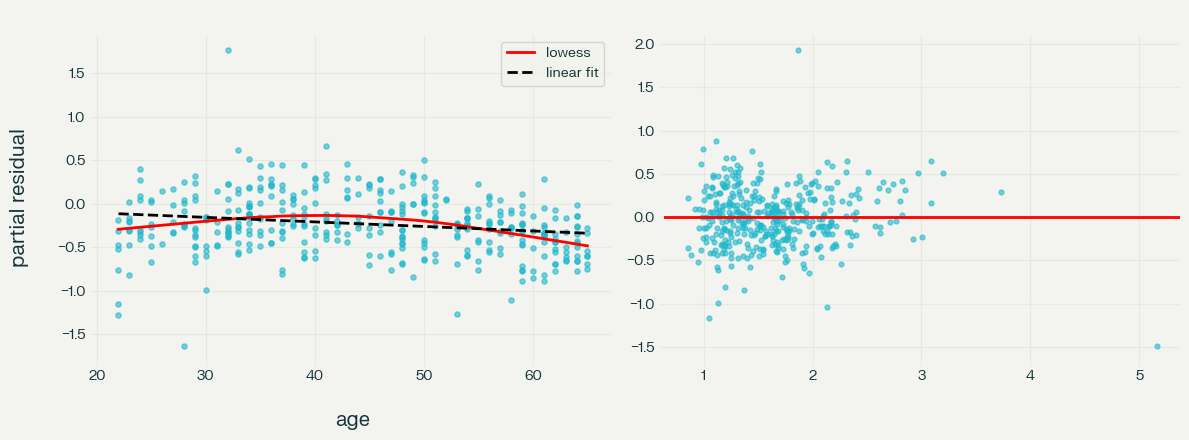

linear coefficient of age: -0.0052
lowess at age 22 : -0.293
lowess at age 30 : -0.201
lowess at age 40 : -0.135
lowess at age 50 : -0.198
lowess at age 60 : -0.382
lowess at age 65 : -0.484


In [ ]:
core=" + income*C(region) + tenure_months + n_products + investments"
mlin=smf.ols("ly ~ age"+core,d).fit()
cpr=mlin.resid+mlin.params["age"]*d.age
fig,ax=plt.subplots(1,2,figsize=(12,4.5))
ax[0].scatter(d.age,cpr,s=14,alpha=.6)
ag=np.linspace(d.age.min(),d.age.max(),200)
lo=sm.nonparametric.lowess(cpr,d.age,frac=.6); ax[0].plot(lo[:,0],lo[:,1],"r",lw=2,label="lowess")
ax[0].plot(ag,mlin.params["age"]*ag+np.mean(cpr-mlin.params["age"]*d.age),"k--",label="linear fit")
ax[0].set_xlabel("age"); ax[0].set_ylabel("partial residual"); ax[0].set_title("Partial residual plot for age"); ax[0].legend()
ax[1].scatter(mlin.fittedvalues,mlin.resid,s=12,alpha=.6); ax[1].axhline(0,c="r"); ax[1].set_title("residuals vs fitted (linear age)")
plt.tight_layout(); show()
print("linear coefficient of age:",round(mlin.params["age"],4))
for a_ in (22,30,40,50,60,65):
    print("lowess at age",a_,":",round(lo[np.argmin(np.abs(lo[:,0]-a_)),1],3))

<div dir="rtl" style="text-align: right;">

lowess از حدود 22 سالگی بالا می رود، از منفی 0.293 تا منفی 0.135 توی 40 سالگی، و بعد پایین می آید تا منفی 0.484 توی 65 سالگی. پایین آمدن بعد از 40 تندتر از بالا رفتن قبلش است. خط راست این شکل را نمی گیرد و ضریب خطی age فقط منفی 0.0052 است، چون بالا رفتن و پایین آمدن همدیگر را تقریبا خنثی می کنند. این ضریب کوچک نشان نمی دهد age بی اثر است.

## چندجمله ای درجه 1 تا 5

درجه های 1 تا 5 را با آزمون F تو در تو مقایسه می کنم، یعنی هر درجه با درجه قبلش. بعد CV ده بخشی با seed ثابت و AIC و BIC را هم کنارش می گذارم.

</div>

In [ ]:
def poly_term(k): return "+".join(["age"]+[f"I(age**{j})" for j in range(2,k+1)])
fits={k:smf.ols("ly ~ "+poly_term(k)+core,d).fit() for k in range(1,6)}
print(anova_lm(*[fits[k] for k in range(1,6)]).round(4))
kf=KFold(10,shuffle=True,random_state=SEED)
def cv_formula(f):
    e=[]
    for tr,te in kf.split(d):
        m=smf.ols(f,d.iloc[tr]).fit(); e.append(((d.ly.iloc[te]-m.predict(d.iloc[te]))**2).mean())
    return np.mean(e),np.std(e)/np.sqrt(10)
tab={}
for k in range(1,6):
    cm_,cs_=cv_formula("ly ~ "+poly_term(k)+core); tab[k]=dict(CV_MSE=cm_,CV_SE=cs_,AIC=fits[k].aic,BIC=fits[k].bic)
tab=pd.DataFrame(tab).T.round(5); tab.index.name="degree"; print(tab.to_string())
print("quadratic term coefficient:",round(fits[2].params["I(age ** 2)"],5))

   df_resid      ssr  df_diff  ss_diff        F  Pr(>F)
0     387.0  44.4469      0.0      NaN      NaN     NaN
1     386.0  40.3568      1.0   4.0901  39.0523  0.0000
2     385.0  40.1542      1.0   0.2026   1.9345  0.1651
3     384.0  40.1478      1.0   0.0064   0.0609  0.8052
4     383.0  40.1134      1.0   0.0344   0.3288  0.5667


         CV_MSE    CV_SE        AIC        BIC
degree                                        
1       0.12882  0.01485  277.34964  317.18901
2       0.11798  0.01379  241.02486  284.84816
3       0.11765  0.01375  241.02672  288.83395
4       0.11851  0.01372  242.96367  294.75484
5       0.11962  0.01385  244.62305  300.39815
quadratic term coefficient: -0.00074


<div dir="rtl" style="text-align: right;">

درجه 1 به 2 معنادار است، F برابر 39.05 و p کمتر از 1e-4. درجه 3 و 4 و 5 چیزی اضافه نمی کنند، p برابر 0.165 و 0.805 و 0.567. BIC درجه 2 را می خواهد، 284.85 در برابر 288.83 برای درجه 3. AIC بین درجه 2 و 3 تقریبا مساوی است، 241.02 و 241.03. CV درجه 3 را ناچیز بهتر می داند، 0.11765 در برابر 0.11798 برای درجه 2، ولی این فرق خیلی کوچک تر از خطای معیار CV است که حدود 0.0138 است. با قاعده یک خطای معیار و برای ساده تر ماندن درجه 2 را انتخاب می کنم. ضریب جمله مربع age منفی است، منفی 0.00074، پس منحنی مقعر است.

## چندجمله ای خام و متعامد

VIF و عدد شرط ستون های توان age را برای نسخه خام و نسخه متعامد حساب می کنم. نسخه متعامد را با تجزیه QR ساختم.

</div>

In [ ]:
a=d.age.values.astype(float)
def vif_poly(k,orth):
    if orth:
        Z=np.column_stack([np.ones(len(a))]+[a**j for j in range(1,k+1)]); Q,_=np.linalg.qr(Z); P=Q[:,1:]*np.sqrt(len(a))
    else: P=np.column_stack([a**j for j in range(1,k+1)])
    X=np.column_stack([np.ones(len(a)),P]); return [vif(X,i) for i in range(1,k+1)],np.linalg.cond(X)
for k in (2,3,5):
    vr,cr_=vif_poly(k,False); vo,co=vif_poly(k,True)
    print(f"degree {k}: raw VIF range=({min(vr):.3g}, {max(vr):.3g}), cond={cr_:.3g} | orthogonal max VIF={max(vo):.3g}, cond={co:.3g}")
f_raw=smf.ols("ly ~ "+poly_term(3)+core,d).fit().fittedvalues
Zo=np.column_stack([np.ones(len(a))]+[a**j for j in range(1,4)]); Qo,_=np.linalg.qr(Zo)
Xrest=np.asarray(dmatrix("income*C(region) + tenure_months + n_products + investments - 1",d))
mo=sm.OLS(d.ly.values,np.column_stack([Qo,Xrest])).fit()
print("max |fitted(raw cubic) - fitted(orthogonal cubic)| =",np.abs(f_raw.values-mo.fittedvalues).max())

degree 2: raw VIF range=(63.1, 63.1), cond=3.21e+04 | orthogonal max VIF=1, cond=1
degree 3: raw VIF range=(1.85e+03, 8.27e+03), cond=6.2e+06 | orthogonal max VIF=1, cond=1
degree 5: raw VIF range=(1.06e+06, 6.04e+07), cond=2.98e+11 | orthogonal max VIF=1, cond=1
max |fitted(raw cubic) - fitted(orthogonal cubic)| = 4.107825191113079e-12


<div dir="rtl" style="text-align: right;">

چندجمله ای خام VIF خیلی بزرگ دارد. درجه 2 حدود 63، درجه 3 بین 1850 و 8270 و درجه 5 بین 1.06e6 و 6.04e7 با عدد شرط حدود 3e11، چون توان های age تقریبا هم جهت اند. توی نسخه متعامد همه VIF ها 1 و عدد شرط 1 است. فضای ستون ها یکی است و برای درجه 3 بیشترین اختلاف مقدار برازش شده بین دو نسخه 4e-12 است، یعنی برازش و آزمون F عوض نمی شوند و فقط پایداری عددی و تفسیر ضرایب فرق می کند. ضریب های خام تک تک تفسیر ندارند.

## اسپلاین طبیعی و B-spline

اسپلاین طبیعی را با پایه خودم ساختم و گره ها را روی چندک های age گذاشتم. K تعداد کل گره ها با دو گره مرزی است. df اسپلاین ها را با همان CV ده بخشی انتخاب می کنم.

</div>

Natural spline K (total knots incl. 2 boundary) -> CV-MSE
{2: 0.12882, 3: 0.11828, 4: 0.11795, 5: 0.11845, 6: 0.11935, 7: 0.11984, 8: 0.12063}
selected: 4
B-spline df -> CV-MSE
{3: 0.11765, 4: 0.11843, 5: 0.11954, 6: 0.11988, 7: 0.12028, 8: 0.11964, 9: 0.11708}
selected: 9 (df=3 means no interior knot = cubic polynomial)


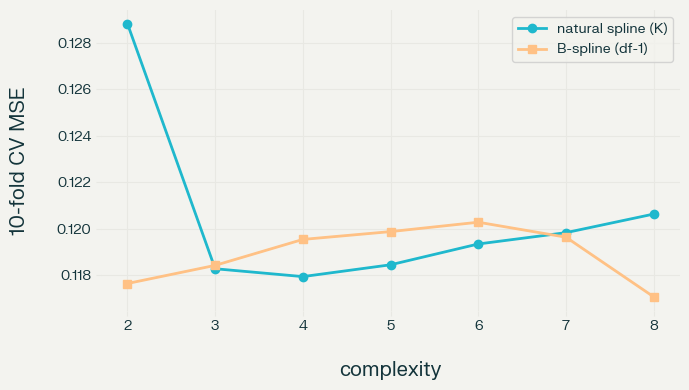

In [ ]:
age=d.age.values.astype(float); yv=d.ly.values
Xo=np.asarray(dmatrix("income*C(region) + tenure_months + n_products + investments",d))
def make_knots(x,K): return np.quantile(x,np.linspace(0,1,K))
def ns_basis(x,xi):
    K=len(xi); dk=lambda k:(np.clip(x-xi[k],0,None)**3-np.clip(x-xi[-1],0,None)**3)/(xi[-1]-xi[k])
    return np.column_stack([x]+[dk(k)-dk(K-2) for k in range(K-2)])
def bs_basis(x,df): return np.asarray(dmatrix(f"bs(a, df={df}, degree=3, include_intercept=False, lower_bound={age.min()}, upper_bound={age.max()}) - 1",{"a":x}))
def basis(kind,k,x=age):
    return ns_basis(x,make_knots(age,k)) if kind=="ns" else bs_basis(x,k)
def cv_B(kind,k):
    X=np.column_stack([Xo,basis(kind,k)]); e=[]
    for tr,te in kf.split(X):
        b=np.linalg.lstsq(X[tr],yv[tr],rcond=None)[0]; e.append(((yv[te]-X[te]@b)**2).mean())
    return np.mean(e)
cv_ns={K:cv_B("ns",K) for K in range(2,9)}
cv_bs={k:cv_B("bs",k) for k in range(3,10)}
best_ns=min(cv_ns,key=cv_ns.get); best_bs=min(cv_bs,key=cv_bs.get)
print("Natural spline K (total knots incl. 2 boundary) -> CV-MSE"); print({k:round(v,5) for k,v in cv_ns.items()}); print("selected:",best_ns)
print("B-spline df -> CV-MSE"); print({k:round(v,5) for k,v in cv_bs.items()}); print("selected:",best_bs,"(df=3 means no interior knot = cubic polynomial)")
fig,ax=plt.subplots(figsize=(7,4))
ax.plot(list(cv_ns),[cv_ns[k] for k in cv_ns],"o-",label="natural spline (K)")
ax.plot([k-1 for k in cv_bs],[cv_bs[k] for k in cv_bs],"s-",label="B-spline (df-1)")
ax.set_xlabel("complexity"); ax.set_ylabel("10-fold CV MSE"); ax.legend(); show()

<div dir="rtl" style="text-align: right;">

CV برای اسپلاین طبیعی کمترین خطا را توی K برابر 4 می دهد، 0.11795، و K برابر 2 همان مدل خطی است، 0.12882. B-spline کمترین CV را توی df برابر 9 دارد، 0.11708، ولی فرقش با df برابر 3 یعنی 0.11765 فقط حدود 0.0006 است که خیلی زیر خطای معیار CV است. df برابر 9 هم برازش پر پیچ و خم می دهد. df برابر 3 توی B-spline یعنی بدون گره داخلی و همان چندجمله ای مکعبی. پس داده بیشتر از یک انحنای ساده را پشتیبانی نمی کند و منحنی CV تقریبا صاف است.

## سن اوج و بوت استرپ

سن اوج را با بوت استرپ 1000 تکراری درمی آورم. هر بار مشاهده ها را با جایگذاری نمونه می گیرم، مدل را دوباره برازش می کنم و سنی که منحنی age توی آن بیشترین است را می نویسم. df همان مقدار انتخاب شده از CV ثابت می ماند. این کار را برای اسپلاین طبیعی و B-spline و چندجمله ای درجه 2 می کنم.

</div>

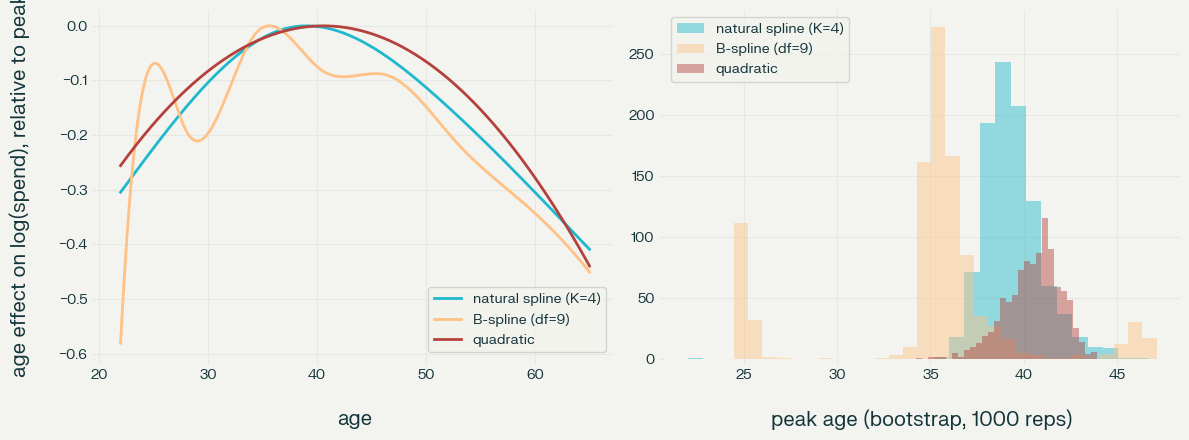

                      peak_age  CI_lo(2.5%)  CI_hi(97.5%)  share_at_boundary
natural spline (K=4)      39.1         37.0          43.2                0.0
B-spline (df=9)           35.6         24.9          46.1                0.0
quadratic                 40.6         37.3          42.9                0.0


In [ ]:
grid=np.linspace(age.min(),age.max(),431)
specs={"natural spline (K=%d)"%best_ns:("ns",best_ns),"B-spline (df=%d)"%best_bs:("bs",best_bs),"quadratic":("poly",2)}
def design_pair(kind,k):
    if kind=="poly": return np.column_stack([age,age**2]),np.column_stack([grid,grid**2])
    return basis(kind,k),basis(kind,k,grid)
rng=np.random.default_rng(SEED); n=len(d); peaks={}
fig,ax=plt.subplots(1,2,figsize=(12,4.5))
for name,(kind,k) in specs.items():
    B,Bg=design_pair(kind,k); X=np.column_stack([Xo,B]); q=Xo.shape[1]
    b=np.linalg.lstsq(X,yv,rcond=None)[0]; curve=Bg@b[q:]; p0=grid[curve.argmax()]
    pk=np.empty(1000)
    for i in range(1000):
        idx=rng.integers(0,n,n); bb=np.linalg.lstsq(X[idx],yv[idx],rcond=None)[0]; pk[i]=grid[(Bg@bb[q:]).argmax()]
    peaks[name]=(p0,*np.percentile(pk,[2.5,97.5]),np.mean((pk<=grid[0]+1e-9)|(pk>=grid[-1]-1e-9)))
    ax[0].plot(grid,curve-curve.max(),label=name)
    ax[1].hist(pk,bins=30,alpha=.45,label=name)
ax[0].set_xlabel("age"); ax[0].set_ylabel("age effect on log(spend), relative to peak"); ax[0].legend()
ax[1].set_xlabel("peak age (bootstrap, 1000 reps)"); ax[1].legend(); plt.tight_layout(); show()
print(pd.DataFrame(peaks,index=["peak_age","CI_lo(2.5%)","CI_hi(97.5%)","share_at_boundary"]).T.round(2).to_string())

<div dir="rtl" style="text-align: right;">

درجه 2 قله 40.6 سال می دهد با فاصله اطمینان 37.3 تا 42.9. اسپلاین طبیعی 39.1 با 37.0 تا 43.2. B-spline با df برابر 9 قله 35.6 می دهد ولی فاصله اش از 24.9 تا 46.1 است که خیلی پهن است و قابل اعتماد نیست. توی هیچ نمونه بوت استرپی قله روی مرز سنی نیفتاد. عددی که گزارش می کنم 40 سال است با فاصله حدود 37 تا 43. چون df ثابت بود، اگر انتخاب df هم توی هر نمونه تکرار می شد فاصله ها کمی پهن تر می شدند.

## آیا tenure_months هم غیرخطی است؟

مدل جمعی ساده می زنم، یعنی age با اسپلاین طبیعی انتخابی و tenure یک بار خطی و یک بار با اسپلاین طبیعی، و دو مدل تو در تو را با F مقایسه می کنم. برای اطمینان تعداد گره tenure را 3 و 4 و 5 گذاشتم.

</div>

In [ ]:
ten=d.tenure_months.values.astype(float)
Xo2=np.asarray(dmatrix("income*C(region) + n_products + investments",d))
Bage=ns_basis(age,make_knots(age,best_ns))
def rss(X): b=np.linalg.lstsq(X,yv,rcond=None)[0]; r=yv-X@b; return (r**2).sum(),X.shape[1]
def ftest(Xs,Xl):
    r0,p0=rss(Xs); r1,p1=rss(Xl); F=((r0-r1)/(p1-p0))/(r1/(len(yv)-p1)); return F,stats.f.sf(F,p1-p0,len(yv)-p1),p1-p0,len(yv)-p1
Xlin=np.column_stack([Xo2,Bage,ten]); out=[]
for K in (3,4,5):
    Xnl=np.column_stack([Xo2,Bage,ns_basis(ten,make_knots(ten,K))]); F,p,d1,d2=ftest(Xlin,Xnl); out.append(dict(tenure_spline_K=K,F=F,df1=d1,df2=d2,p=p))
print(pd.DataFrame(out).round(4).to_string())
F,p,d1,d2=ftest(np.column_stack([Xo2,ten,age]),np.column_stack([Xo2,ten,Bage]))
print(f"age: linear vs spline (tenure linear): F={F:.2f}, p={p:.2e}")

   tenure_spline_K       F  df1  df2       p
0                3  1.2937    1  384  0.2561
1                4  0.7592    2  383  0.4687
2                5  0.9223    3  382  0.4300
age: linear vs spline (tenure linear): F=20.25, p=4.34e-09


<div dir="rtl" style="text-align: right;">

هیچ کدام معنادار نیستند، p برابر 0.256 و 0.469 و 0.430. پس شواهدی نیست که tenure_months غیرخطی باشد و خطی نگهش می دارم. همین آزمون را برای age زدم و F برابر 20.25 و p حدود 4e-9 شد، پس غیرخطی بودن age قطعی است ولی tenure نه. این نبود شواهد است و اثبات خطی بودن نیست، چون با 397 مشاهده توان آزمون برای انحنای کوچک محدود است.

## حساسیت به انتخاب مشاهده ها

همه چیز را با سه مجموعه دوباره می زنم. سه تا با بیشترین Cook، مجموعه 311 و 368 و 152 که توی کوییز 1 باقی مانده های لگاریتمی را خراب می کردند، و هر پنج مشاهده تاثیرگذار کوییز 1.

</div>

In [ ]:
def summarize(ids,label):
    dd=raw[~raw.id.isin(ids)].copy(); dd["ly"]=np.log(dd.monthly_spend)
    a0=smf.ols(base,dd).fit(); a1=smf.ols(base+" + income:C(region)",dd).fit(); Fi,pi,_=a1.compare_f_test(a0)
    sl=region_slopes(a1)
    qf=[smf.ols("ly ~ "+poly_term(k)+core,dd).fit() for k in (1,2,3)]; an=anova_lm(*qf)
    q2=qf[1]; peak=-q2.params["age"]/(2*q2.params["I(age ** 2)"])
    return dict(set=label,n=len(dd),interaction_p=pi,
        Tehran_pct_CI=f"({sl.loc['Tehran','pct_lo']:.2f}, {sl.loc['Tehran','pct_hi']:.2f})",
        Metro_pct_CI=f"({sl.loc['Metro','pct_lo']:.2f}, {sl.loc['Metro','pct_hi']:.2f})",
        Other_pct_CI=f"({sl.loc['Other','pct_lo']:.2f}, {sl.loc['Other','pct_hi']:.2f})",
        p_deg2=an["Pr(>F)"].iloc[1],p_deg3=an["Pr(>F)"].iloc[2],quad_peak_age=peak)
print(pd.DataFrame([summarize(INFLUENTIAL,f"top-3 Cook {INFLUENTIAL}"),summarize([311,368,152],"[311, 368, 152]"),summarize([311,368,84,152,32],"all five of Quiz 1")]).round(4).T.to_string())

                                       0                1                   2
set            top-3 Cook [311, 368, 84]  [311, 368, 152]  all five of Quiz 1
n                                    397              397                 395
interaction_p                        0.0              0.0                 0.0
Tehran_pct_CI               (2.32, 2.94)     (2.32, 2.90)        (2.84, 3.55)
Metro_pct_CI                (1.17, 2.04)     (1.17, 2.03)        (1.18, 2.01)
Other_pct_CI                (0.31, 1.05)     (0.84, 1.80)        (0.87, 1.79)
p_deg2                               0.0              0.0                 0.0
p_deg3                            0.1642           0.3205              0.3719
quad_peak_age                    40.6075          40.3926             40.5898


<div dir="rtl" style="text-align: right;">

نتیجه های اصلی توی هر سه مجموعه یکی است، یعنی اثر متقابل خیلی معنادار، درجه 2 کافی و قله حدود 40.4 تا 40.6 سال. دو چیز به انتخاب وابسته است. اول شیب income توی Other، که با نگه داشتن 152 فاصله اطمینانش 0.31 تا 1.05 درصد است و با حذف 152 می شود 0.84 تا 1.80، چون 152 یک مشتری Other با درآمد 150 و خرج 3 است. دوم شیب تهران، که با حذف 84 یا 152 تقریبا ثابت می ماند، 2.32 تا 2.94 و 2.32 تا 2.90، ولی با حذف هر پنج تا می شود 2.84 تا 3.55. چون حذف 84 کاری نکرد، id 32 که تهرانی با درآمد 160 است باعث این فرق می شود. توی گزارش هر دو را می نویسم، با دلیل انتخاب سه تا با بیشترین Cook.

</div>

<div dir="rtl" style="text-align: right;">

### 5. سوال 1-ج (مفهومی)

## i) تعداد پارامترها

اسپلاین مکعبی با K گره داخلی بازه را به K به اضافه 1 تکه می کند و روی هر تکه یک چندجمله ای درجه 3 است که 4 ضریب دارد، پس 4 ضرب در K به اضافه 1 ضریب داریم. توی هر گره خود تابع و مشتق اول و مشتق دوم باید پیوسته باشند، یعنی 3 قید توی هر گره و 3 ضرب در K قید در کل. 4K به اضافه 4 منهای 3K می شود K به اضافه 4. همین را با پایه توان های بریده هم می شود دید، یعنی ثابت و x و مربع و مکعب و برای هر گره یک جمله مکعبی بریده، که می شود K به اضافه 4 تابع مستقل.

اسپلاین طبیعی باید بیرون از دو گره مرزی خطی باشد، یعنی مشتق دوم و سوم آنجا صفر. سمت چپ دو قید می دهد چون ضریب جمله مربع و مکعب باید صفر باشد. سمت راست همین دو شرط را می خواهد ولی با پایه توان های بریده این دو شرط دو معادله روی ضریب جمله های بریده می شود، یکی جمع ضریب ها برابر صفر و یکی جمع ضریب ها ضرب در محل گره ها برابر صفر. پس 4 قید مستقل داریم و بعد می شود K به اضافه 4 منهای 4، یعنی K. این K با عرض از مبدا حساب شده، بدون عرض از مبدا K منهای 1 ستون می ماند که توی کدم همان است.

یک نکته درباره صورت سوال، K اینجا باید تعداد کل گره ها با دو گره مرزی باشد، همان قرارداد کتاب ESL فصل 5. اگر K فقط گره های داخلی باشد و گره های مرزی جدا حساب شوند، بعد اسپلاین طبیعی K به اضافه 2 می شود. فرمول صورت سوال با قرارداد اول جور است و من همین را فرض کردم.

## ii) پدیده Runge و قید خطی

واریانس برازش توی هر نقطه برابر واریانس خطا ضرب اهرم همان نقطه است. توی چندجمله ای درجه بالا هر ضریب روی کل بازه اثر می گذارد و ستون های x و مربع و مکعب و ... تقریبا هم جهت اند، برای همین بیشتر درجه آزادی ها خرج کنترل شکل منحنی توی دو سر بازه می شود. طبق نتیجه شناخته شده درباره چندجمله ای های لژاندر، اهرم توی دو سر بازه از مرتبه مربع درجه تقسیم بر n است و وسط بازه از مرتبه خود درجه تقسیم بر n، پس دو سر بازه خیلی بیشتر نوسان می کند. اسپلاین طبیعی بیرون از گره های مرزی خطی است و از هر سر دو درجه آزادی، یعنی جمله مربع و مکعب را حذف می کند، پس منحنی توی مرز با یک خط کنترل می شود و واریانس مرزی کم می شود. بهایش کمی اریبی توی مرز است چون شکل خطی را به منحنی تحمیل کرده ایم. چک عددی پایین فقط نشان می دهد اهرم دو سر برای چندجمله ای بیشتر است، خود مرتبه مربع درجه را عددی چک نکرده ام.

## iii) رد ماتریس هموارساز

ماتریس هموارساز تصویر عمود روی فضای ستون های پایه است. متقارن است و اگر دو بار اعمال شود فرقی نمی کند، یعنی خودتوان است، برای همین مقدارهای ویژه اش فقط صفر و یک اند و تعداد یک ها برابر رتبه پایه است. رد ماتریس جمع مقدارهای ویژه اش است، پس رد برابر تعداد ستون های مستقل پایه می شود، یعنی تعداد پارامترهای آزاد برازش. از زاویه دیگر هم می شود دید، کوواریانس مقدار برازش شده مشاهده i با خود y مشاهده i برابر واریانس خطا ضرب درایه قطری i ماتریس هموارساز است و جمع این کوواریانس ها تقسیم بر واریانس خطا همان رد ماتریس می شود. یعنی رد مقدار حساسیت کل برازش به داده است و برای هموارسازهای جریمه دار هم همین تعریف به کار می رود.

اگر تعداد و جای گره ها از قبل ثابت باشد و فقط از x ساخته شوند، ماتریس هموارساز به y بستگی ندارد و برازش یک تابع خطی از y است، یعنی برازش جمع دو پاسخ برابر جمع برازش هاست و فرمول معمول واریانس و F و فاصله اطمینان دقیق است. اگر df را با CV از روی y انتخاب کنیم خود ماتریس هموارساز به y بستگی پیدا می کند، پس نگاشت از y به برازش فقط تکه تکه خطی است و جمع پذیر نیست چون با y های مختلف df انتخابی فرق می کند. رد ماتریس هم تصادفی می شود و F و فاصله اطمینان هایی که انتخاب df را نادیده می گیرند خوش بین می شوند. برای همین توی بوت استرپ باید انتخاب df را هم هر بار تکرار کنیم یا df را ثابت گزارش کنیم که من ثابت گزارش کردم.

برای چک عددی ماتریس هموارساز را با ضرب ماتریس ها برای سه پایه می سازم و با QR مقایسه می کنم، رد و اهرم دو سر سن را می نویسم و جمع پذیر بودن را یک بار با df ثابت و یک بار با df انتخابی از CV امتحان می کنم. دو پاسخ آزمایشی را از خود log خرج با کمی نویز ساختم.

</div>

In [ ]:
def S_from(B):
    return B@np.linalg.inv(B.T@B)@B.T          # S = B (B^T B)^{-1} B^T, built explicitly with matrices
def S_qr(B):
    Q,_=np.linalg.qr(B); return Q@Q.T          # numerically stable cross-check
B5=np.column_stack([np.ones(n)]+[(age-age.mean())**j/(age.std()**j) for j in range(1,6)])
Bn=np.column_stack([np.ones(n),ns_basis(age,make_knots(age,6))])
Bc=np.column_stack([np.ones(n),bs_basis(age,7)])
for nm,B in (("poly deg5",B5),("natural K=6",Bn),("cubic B-spline df=7",Bc)):
    S=S_from(B); i_lo=age.argmin(); i_hi=age.argmax()
    print(f"{nm:20s} tr(S)={np.trace(S):.4f} rank(B)={np.linalg.matrix_rank(B)} sym={np.allclose(S,S.T)} idem={np.allclose(S@S,S,atol=1e-6)} max|S-S_qr|={np.abs(S-S_qr(B)).max():.1e}")
    print(f"{'':20s} leverage at min/max age: {S[i_lo,i_lo]:.4f}/{S[i_hi,i_hi]:.4f} | median leverage {np.median(np.diag(S)):.4f}")
def cv_pick(yvec):
    sc={}
    for K in (2,3,4,6):
        X=np.column_stack([Xo,ns_basis(age,make_knots(age,K))]); e=[]
        for tr,te in kf.split(X):
            b=np.linalg.lstsq(X[tr],yvec[tr],rcond=None)[0]; e.append(((yvec[te]-X[te]@b)**2).mean())
        sc[K]=np.mean(e)
    return min(sc,key=sc.get)
def fit_sel(yvec):
    K=cv_pick(yvec); X=np.column_stack([Xo,ns_basis(age,make_knots(age,K))]); return X@np.linalg.lstsq(X,yvec,rcond=None)[0],K
rs=np.random.default_rng(1); y1_=yv+rs.normal(0,.3,len(yv)); y2_=yv[::-1].copy()+rs.normal(0,.3,len(yv))
fa,Ka=fit_sel(y1_); fb,Kb=fit_sel(y2_); fc,Kc=fit_sel(y1_+y2_)
print("chosen K for y1,y2,y1+y2:",Ka,Kb,Kc,"| max|fit(y1+y2)-fit(y1)-fit(y2)| =",np.abs(fc-fa-fb).max())
Xfix=np.column_stack([Xo,ns_basis(age,make_knots(age,3))]); Sx=S_from(Xfix)
print("fixed K=3: max|S(y1+y2)-S y1-S y2| =",np.abs(Sx@(y1_+y2_)-Sx@y1_-Sx@y2_).max())

poly deg5            tr(S)=6.0000 rank(B)=6 sym=True idem=True max|S-S_qr|=5.2e-15
                     leverage at min/max age: 0.0753/0.0650 | median leverage 0.0105
natural K=6          tr(S)=6.0000 rank(B)=6 sym=True idem=True max|S-S_qr|=9.9e-13
                     leverage at min/max age: 0.0487/0.0427 | median leverage 0.0130
cubic B-spline df=7  tr(S)=8.0000 rank(B)=8 sym=True idem=True max|S-S_qr|=6.1e-16
                     leverage at min/max age: 0.0908/0.0878 | median leverage 0.0162


chosen K for y1,y2,y1+y2: 4 2 3 | max|fit(y1+y2)-fit(y1)-fit(y2)| = 0.16899084954429644
fixed K=3: max|S(y1+y2)-S y1-S y2| = 2.886579864025407e-15


<div dir="rtl" style="text-align: right;">

ماتریس هموارساز برای هر سه پایه متقارن و خودتوان است و ردش برابر تعداد ستون هاست، 6 و 6 و 8. B-spline با df برابر 7 همراه عرض از مبدا 8 ستون دارد. فرق ماتریس ساخته شده با ضرب ماتریس ها و روش QR حداکثر حدود 1e-12 است.

اهرم دو سر سن برای چندجمله ای درجه 5 که 6 پارامتر دارد 0.0753 و 0.0650 است و میانه اهرم 0.0105، یعنی حدود 7 برابر. برای اسپلاین طبیعی با K برابر 6 که آن هم 6 پارامتر دارد 0.0487 و 0.0427 است با میانه 0.0130، یعنی حدود 3.5 برابر. با همان تعداد پارامتر اهرم مرزی چندجمله ای بیشتر است، که با بند ii می خورد.

با df ثابت برابر 3 فرق برازش جمع دو پاسخ با جمع برازش ها حدود 3e-15 است، یعنی صفر. وقتی df با CV انتخاب می شود، K برای پاسخ اول و دوم و جمع شان 4 و 2 و 3 شد و فرق به 0.17 می رسد. پس با انتخاب df از روی داده برازش خطی نیست.

</div>

<div dir="rtl" style="text-align: right;">

### 6. سوال 2-الف: جدایی توی لجستیک

مدل لجستیک را با debt_ratio و late_payments و income و age و tenure_months و region و legal_case می زنم و اول جدول متقاطع legal_case و default را نگاه می کنم.

</div>

In [ ]:
y=raw.default.values
form_full="default ~ debt_ratio + late_payments + income + age + tenure_months + C(region) + legal_case"
form_red ="default ~ debt_ratio + late_payments + income + age + tenure_months + C(region)"
Xf=dmatrix(form_full.split("~")[1],raw,return_type="dataframe"); namesf=list(Xf.columns); Xa=Xf.values
Xr_=dmatrix(form_red.split("~")[1],raw,return_type="dataframe"); namesr=list(Xr_.columns); Xra=Xr_.values
print(pd.crosstab(raw.legal_case,raw.default,margins=True))
full=sm.GLM(y,Xa,family=sm.families.Binomial()).fit(maxiter=100)
print(pd.DataFrame({"coef":full.params,"se":full.bse,"z(Wald)":full.tvalues,"p":full.pvalues},index=namesf).round(4))

default       0   1  All
legal_case              
0           312  73  385
1             0  15   15
All         312  88  400
                       coef          se  z(Wald)       p
Intercept           -2.0300      0.7635  -2.6587  0.0078
C(region)[T.Metro]  -0.1872      0.3169  -0.5908  0.5546
C(region)[T.Other]  -0.7223      0.3573  -2.0214  0.0432
debt_ratio           3.0349      0.8781   3.4563  0.0005
late_payments        0.6704      0.1490   4.5002  0.0000
income              -0.0151      0.0093  -1.6161  0.1061
age                  0.0003      0.0163   0.0174  0.9861
tenure_months       -0.0070      0.0073  -0.9611  0.3365
legal_case          24.0869  11770.5387   0.0020  0.9984


<div dir="rtl" style="text-align: right;">

هر 15 مشتری با legal_case برابر 1 نکول کرده اند و هیچ کدام غیرنکول نیست، یعنی یک خانه خالی توی جدول داریم. این جدایی شبه کامل است. نرم افزار خطا نمی دهد ولی ضریب legal_case را 24.09 با SE برابر 11770 می دهد و z حدود 0.002 و p برابر 0.998 می شود، یعنی Wald می گوید legal_case اثر ندارد که غلط است.

IRLS را خودم دستی اجرا می کنم و توی هر تکرار لگاریتم درستنمایی و ضریب و SE legal_case و کمترین وزن را می نویسم.

</div>

In [ ]:
beta=np.zeros(Xa.shape[1]); beta[0]=np.log(y.mean()/(1-y.mean())); j=namesf.index("legal_case"); tr=[]
for it in range(1,31):
    eta=Xa@beta; p=1/(1+np.exp(-eta)); w=p*(1-p)
    ll=np.sum(y*np.log(p)+(1-y)*np.log(1-p))
    z=eta+(y-p)/w; XtW=Xa.T*w; beta=np.linalg.solve(XtW@Xa,XtW@z)
    se_j=np.sqrt(np.diag(np.linalg.inv((Xa.T*w)@Xa)))[j]
    tr.append(dict(iter=it,loglik=ll,beta_legal=beta[j],se_legal=se_j,min_weight=w.min()))
irls=pd.DataFrame(tr).set_index("iter"); print(irls.iloc[[0,1,2,3,4,9,14,19,24,29]].round(6))
red=sm.GLM(y,Xra,family=sm.families.Binomial()).fit()
sub=raw.legal_case.values==0
ll_sub=sm.GLM(y[sub],Xra[sub],family=sm.families.Binomial()).fit().llf
LR=2*(irls.loglik.iloc[-1]-red.llf)
print(f"limit logLik of full model = {irls.loglik.iloc[-1]:.4f} | logLik of reduced model on legal_case=0 subset = {ll_sub:.4f}")
print(f"LRT for legal_case: LR={LR:.2f}, df=1, p={stats.chi2.sf(LR,1):.2e}")
print(f"Wald: z={full.tvalues[j]:.4f}, p={full.pvalues[j]:.4f}")

          loglik  beta_legal      se_legal  min_weight
iter                                                  
1    -210.763185    4.483321  6.460820e-01    0.171600
2    -171.537802    5.738884  1.300287e+00    0.013762
3    -169.678026    6.794997  2.105783e+00    0.003569
4    -169.495459    7.804259  3.449768e+00    0.001225
5    -169.441244    8.807322  5.673976e+00    0.000447
10   -169.410201   13.809085  6.902620e+01    0.000003
15   -169.409993   18.809097  8.409033e+02    0.000000
20   -169.409991   23.809097  1.024430e+04    0.000000
25   -169.409991   28.809097  1.248011e+05    0.000000
30   -169.409991   33.809097  1.519717e+06    0.000000
limit logLik of full model = -169.4100 | logLik of reduced model on legal_case=0 subset = -169.4100
LRT for legal_case: LR=44.74, df=1, p=2.25e-11
Wald: z=0.0020, p=0.9984


<div dir="rtl" style="text-align: right;">

ضریب legal_case هر تکرار تقریبا یک واحد بزرگ تر می شود، 4.48 و 5.74 و 6.79 و 7.80 و همین طور تا 33.8 توی تکرار 30، و همگرا نمی شود. SE از 0.65 توی تکرار اول به 1.5e6 می رسد و کمترین وزن به صفر می رود. لگاریتم درستنمایی از منفی 210.76 به منفی 171.54 و منفی 169.68 می رود و روی منفی 169.41 می ایستد، نه روی صفر. دلیلش این است که جدایی فقط شبه کامل است و ردیف های legal_case برابر 1 با احتمال برازش شده 1 هیچ سهمی توی لگاریتم درستنمایی ندارند. همین مقدار با لگاریتم درستنمایی مدل بدون legal_case روی 385 مشتری بدون پرونده برابر است، منفی 169.41 در هر دو.

Wald ضریب را به SE تقسیم می کند و SE از ماتریس اطلاعات می آید. وقتی وزن ردیف ها به صفر می رود اطلاعات توی جهت legal_case تقریبا صفر می شود و SE منفجر می شود، پس z به صفر می رسد. لگاریتم درستنمایی هم توی این جهت قله ندارد و فقط بالا می رود، پس فرض نرمال بودن شکلش برقرار نیست. آزمون نسبت درستنمایی فقط مقدار درستنمایی را نگاه می کند. آماره 44.74 با یک درجه آزادی و p حدود 2.2e-11 است. یعنی legal_case خیلی معنادار است و Wald همین را پنهان کرده بود.

</div>

<div dir="rtl" style="text-align: right;">

### 7. سوال 2-ب: حل مشکل

مشکل را سه جور حل می کنم و کنار هم می گذارم، حذف متغیر و Firth و Ridge. جریمه Jeffreys برای Firth را خودم پیاده کردم و برای فاصله اطمینان ضریب legal_case از درستنمایی نیم رخ جریمه شده استفاده کردم چون Wald برای Firth هم دقیق نیست. برای Ridge ستون های عددی را استاندارد کردم و λ را با CV ده بخشی و log-loss انتخاب می کنم. sklearn با C کار می کند که معکوس λ است.

</div>

In [ ]:
def firth(X,y,maxit=200,tol=1e-10):
    b=np.zeros(X.shape[1]); b[0]=np.log(y.mean()/(1-y.mean()))
    for i in range(maxit):
        eta=X@b; p=1/(1+np.exp(-eta)); w=p*(1-p); inv=np.linalg.inv((X.T*w)@X)
        h=w*np.einsum("ij,jk,ik->i",X,inv,X)
        step=inv@(X.T@(y-p+h*(0.5-p))); mx=np.abs(step).max()
        if mx>5: step*=5/mx
        b=b+step
        if np.abs(step).max()<tol: break
    eta=X@b; p=1/(1+np.exp(-eta)); w=p*(1-p); cov=np.linalg.inv((X.T*w)@X)
    return b,np.sqrt(np.diag(cov)),i+1
def firth_pen_ll(X,y,b):
    eta=X@b; p=1/(1+np.exp(-eta)); w=p*(1-p)
    return np.sum(y*np.log(p)+(1-y)*np.log(1-p))+0.5*np.linalg.slogdet((X.T*w)@X)[1]
bF,seF,itF=firth(Xa,y)
from scipy.optimize import brentq
def prof(bj):
    keep=[i for i in range(Xa.shape[1]) if i!=j]; off=Xa[:,j]*bj
    b=np.zeros(len(keep)); b[0]=-1.5
    for _ in range(100):
        Xk=Xa[:,keep]; eta=Xk@b+off; p=1/(1+np.exp(-eta)); w=p*(1-p); inv=np.linalg.inv((Xk.T*w)@Xk)
        h=w*np.einsum("ij,jk,ik->i",Xk,inv,Xk); st=inv@(Xk.T@(y-p+h*(0.5-p)))
        mx=np.abs(st).max(); st=st*(3/mx) if mx>3 else st; b=b+st
        if np.abs(st).max()<1e-9: break
    full_b=np.zeros(Xa.shape[1]); full_b[keep]=b; full_b[j]=bj
    return firth_pen_ll(Xa,y,full_b)
l_hat=firth_pen_ll(Xa,y,bF); crit=l_hat-stats.chi2.ppf(.95,1)/2
lo_=brentq(lambda t:prof(t)-crit,0.5,bF[j]); hi_=brentq(lambda t:prof(t)-crit,bF[j],14)
cols=[c for c in namesf if c!="Intercept"]; Xs=Xa[:,1:].copy()
cont=[cols.index(c) for c in ["debt_ratio","late_payments","income","age","tenure_months"]]
mu=Xs[:,cont].mean(0); sd=Xs[:,cont].std(0); Xs[:,cont]=(Xs[:,cont]-mu)/sd
cv10=StratifiedKFold(10,shuffle=True,random_state=SEED)
Cs=np.logspace(-2,4,50)
gs=GridSearchCV(LogisticRegression(penalty="l2",max_iter=20000),{"C":Cs},cv=cv10,scoring="neg_log_loss").fit(Xs,y)
sc=-gs.cv_results_["mean_test_score"]; se=gs.cv_results_["std_test_score"]/np.sqrt(10); imin=sc.argmin(); i1=np.where(sc<=sc[imin]+se[imin])[0].min()
def ridge_raw(Cv):
    m=LogisticRegression(penalty="l2",C=Cv,max_iter=20000).fit(Xs,y); b=m.coef_[0].copy(); b0=m.intercept_[0]
    for jj,c in enumerate(cont): b[c]=b[c]/sd[jj]; b0-=b[c]*mu[jj]
    return np.r_[b0,b]
cmp=pd.DataFrame({"MLE full":full.params,"Firth":bF,"Ridge (min CV)":ridge_raw(Cs[imin]),"Ridge (1-SE)":ridge_raw(Cs[i1])},index=namesf)
cmp["Drop legal_case"]=pd.Series(np.asarray(red.params),index=namesr)
print("lambda=1/C : min-CV lambda=%.2g (C=%.3g) | 1-SE lambda=%.3g (C=%.3g)"%(1/Cs[imin],Cs[imin],1/Cs[i1],Cs[i1]))
print(cmp.round(3).to_string()); print("SE of legal_case coef - MLE: %.0f | Firth: %.2f"%(full.bse[j],seF[j]))
print("legal_case Firth: beta=%.2f, profile-likelihood 95%% CI for beta=(%.2f, %.2f) -> OR=%.0f (%.1f, %.0f)"%(bF[j],lo_,hi_,np.exp(bF[j]),np.exp(lo_),np.exp(hi_)))
print("Ridge 1-SE OR(legal_case)=%.1f"%np.exp(ridge_raw(Cs[i1])[-1]))

lambda=1/C : min-CV lambda=0.00023 (C=4.29e+03) | 1-SE lambda=1.46 (C=0.687)
                    MLE full  Firth  Ridge (min CV)  Ridge (1-SE)  Drop legal_case
Intercept             -2.030 -2.021          -2.028        -1.934           -1.957
C(region)[T.Metro]    -0.187 -0.182          -0.185        -0.105           -0.095
C(region)[T.Other]    -0.722 -0.686          -0.719        -0.478           -0.348
debt_ratio             3.035  2.947           3.038         2.886            3.259
late_payments          0.670  0.653           0.671         0.620            0.646
income                -0.015 -0.014          -0.015        -0.015           -0.018
age                    0.000  0.001           0.000        -0.001            0.001
tenure_months         -0.007 -0.007          -0.007        -0.005           -0.006
legal_case            24.087  4.978           9.616         2.484              NaN
SE of legal_case coef - MLE: 11771 | Firth: 1.50
legal_case Firth: beta=4.98, profile-likelih

<div dir="rtl" style="text-align: right;">

ضریب های بقیه متغیرها توی همه روش ها نزدیک اند، مثلا debt_ratio حدود 2.95 توی Firth و 3.26 توی مدل بدون legal_case، و late_payments حدود 0.65. ضریب legal_case ولی هر جور حل شود فرق می کند. Firth 4.98 با SE برابر 1.50 و فاصله اطمینان 95 درصد 2.89 تا 9.83 می دهد که OR حدود 145 با فاصله 18 تا حدود 18600 می شود. Ridge با λ انتخابی ساده CV برابر 9.62 می دهد و Ridge با قاعده یک خطای معیار 2.48 که OR حدود 12 می شود. CV تقریبا هیچ جریمه ای نمی خواهد، λ حدود 0.00023 و ته گرید، چون legal_case توی هر fold هم نکول را کامل پیش بینی می کند. با قاعده یک خطای معیار λ برابر 1.46 می شود. پس عدد legal_case به روش وابسته است و فقط می شود گفت جهتش مثبت و خیلی بزرگ است.

آیا باید توی مدل باشد؟ به نظرم نه. پرونده حقوقی معمولا موقع وصول مطالبات باز می شود، یعنی همزمان یا بعد از نکول، و موقعی که می خواهیم ریسک را پیش بینی کنیم هنوز وجود ندارد. نکول شدن صد در صد پرونده دارها هم نشانه نشت برچسب است، یعنی legal_case پیامد نکول است نه دلیلش. CV هم این را نمی گیرد چون نشت توی foldهای کنار گذاشته هم هست و برای همین جریمه را تقریبا صفر کرد. این استدلال تفسیر خودم از کسب و کار است و از داده ثابت نمی شود، تاریخ باز شدن پرونده را باید از منبع داده پرسید. اگر هدف فقط توصیف بود، مثلا نکول بین دارندگان پرونده، مدل Firth قابل گزارش است ولی مدل پیش بینی نباید legal_case داشته باشد.

</div>

<div dir="rtl" style="text-align: right;">

### 8. سوال 2-ج: مدل بدون legal_case

OR با فاصله اطمینان 95 درصد برای ده صدم افزایش debt_ratio و یک تاخیر بیشتر را حساب می کنم، اثر متقابل debt_ratio و region را با آزمون نسبت درستنمایی می سنجم و بعد معیارهای برازش و جدول طبقه بندی را می نویسم.

</div>

OR for +0.1 in debt_ratio: 1.385 CI95=(1.183, 1.622)
OR for +1 late payment:     1.908 CI95=(1.454, 2.504)
LRT debt_ratio x region: LR=1.99, df=2, p=0.370
  Tehran  OR(+0.1 debt_ratio)=1.591 CI95=(1.233, 2.053)
  Metro   OR(+0.1 debt_ratio)=1.296 CI95=(0.997, 1.685)
  Other   OR(+0.1 debt_ratio)=1.255 CI95=(0.948, 1.663)
McFadden R2=0.0901 | deviance=383.56 | null deviance=421.53 (drop=37.97, df=7) | AUC=0.700
10-fold CV AUC=0.667
        pred 0  pred 1
true 0     305       7
true 1      82       6
accuracy=0.777 (all-zero baseline: 0.780) | sensitivity=0.068 | specificity=0.978 | precision=0.462
threshold 0.22: sens=0.64 spec=0.66 TP=56 FP=107
threshold 0.25: sens=0.56 spec=0.73 TP=49 FP=85
threshold 0.3: sens=0.45 spec=0.81 TP=40 FP=59


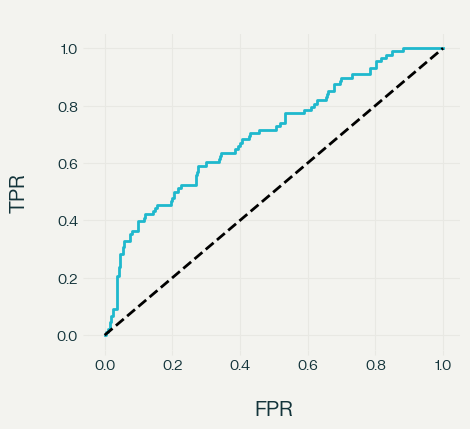

OR vs RR: late_payments OR=1.908, p0=0.220 -> p1=0.350, RR=1.590; check RR=OR/(1-p0+p0*OR)=1.590
OR=2, p0=0.20 -> p1=0.3333, RR=1.667 ; RR=2 needs OR=2.667


In [ ]:
ci=red.conf_int(); jd=namesr.index("debt_ratio"); jl=namesr.index("late_payments")
print("OR for +0.1 in debt_ratio: %.3f CI95=(%.3f, %.3f)"%(np.exp(.1*red.params[jd]),*np.exp(.1*ci[jd])))
print("OR for +1 late payment:     %.3f CI95=(%.3f, %.3f)"%(np.exp(red.params[jl]),*np.exp(ci[jl])))
Xin=dmatrix((form_red+" + debt_ratio:C(region)").split("~")[1],raw,return_type="dataframe"); nin=list(Xin.columns)
gi=sm.GLM(y,Xin.values,family=sm.families.Binomial()).fit(); LRi=2*(gi.llf-red.llf)
print("LRT debt_ratio x region: LR=%.2f, df=2, p=%.3f"%(LRi,stats.chi2.sf(LRi,2)))
cov=gi.cov_params()
for r in ["Tehran","Metro","Other"]:
    Lv=np.zeros(len(nin)); Lv[nin.index("debt_ratio")]=1
    if r!="Tehran": Lv[nin.index(f"debt_ratio:C(region)[T.{r}]")]=1
    est=Lv@gi.params; s=np.sqrt(Lv@cov@Lv); print(f"  {r:7s} OR(+0.1 debt_ratio)=%.3f CI95=(%.3f, %.3f)"%(np.exp(.1*est),*np.exp(.1*(est+np.array([-1.96,1.96])*s))))
null=sm.GLM(y,np.ones((len(y),1)),family=sm.families.Binomial()).fit()
ph=red.predict(Xra)
print("McFadden R2=%.4f | deviance=%.2f | null deviance=%.2f (drop=%.2f, df=%d) | AUC=%.3f"%(1-red.llf/null.llf,red.deviance,null.deviance,null.deviance-red.deviance,len(namesr)-1,roc_auc_score(y,ph)))
pcv=cross_val_predict(LogisticRegression(penalty=None,max_iter=5000),Xra[:,1:],y,cv=cv10,method="predict_proba")[:,1]
print("10-fold CV AUC=%.3f"%roc_auc_score(y,pcv))
cm=confusion_matrix(y,(ph>=.5).astype(int)); tn,fp,fn,tp=cm.ravel()
print(pd.DataFrame(cm,index=["true 0","true 1"],columns=["pred 0","pred 1"]))
print("accuracy=%.3f (all-zero baseline: %.3f) | sensitivity=%.3f | specificity=%.3f | precision=%.3f"%((tn+tp)/len(y),1-y.mean(),tp/(tp+fn),tn/(tn+fp),tp/(tp+fp)))
for t in (.22,.25,.30):
    c=confusion_matrix(y,(ph>=t).astype(int)); print(f"threshold {t}: sens={c[1,1]/c[1].sum():.2f} spec={c[0,0]/c[0].sum():.2f} TP={c[1,1]} FP={c[0,1]}")
fpr,tpr,_=roc_curve(y,ph); plt.figure(figsize=(4.8,4.4)); plt.plot(fpr,tpr); plt.plot([0,1],[0,1],"k--"); plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title("ROC (model without legal_case)"); show()
p0_=y.mean(); orl=np.exp(red.params[jl]); p1_=orl*p0_/(1-p0_+orl*p0_)
print("OR vs RR: late_payments OR=%.3f, p0=%.3f -> p1=%.3f, RR=%.3f; check RR=OR/(1-p0+p0*OR)=%.3f"%(orl,p0_,p1_,p1_/p0_,orl/(1-p0_+p0_*orl)))
print("OR=2, p0=0.20 -> p1=%.4f, RR=%.3f ; RR=2 needs OR=%.3f"%(2*.2/(.8+.4),(2*.2/(.8+.4))/.2,(.4/.6)/(.2/.8)))

<div dir="rtl" style="text-align: right;">

OR برای 0.1 افزایش debt_ratio برابر 1.385 با فاصله اطمینان 1.183 تا 1.622 است و برای یک تاخیر بیشتر 1.908 با 1.454 تا 2.504. اثر متقابل debt_ratio و region معنادار نیست، آماره 1.99 با دو درجه آزادی و p برابر 0.370. OR جدا برای هر منطقه توی تهران 1.591 با 1.233 تا 2.053، توی Metro 1.296 با 0.997 تا 1.685 و توی Other 1.255 با 0.948 تا 1.663 است. چون اثر متقابل معنادار نیست این فرق ها را فقط توصیفی می گیرم و مدل بدون اثر متقابل را نگه می دارم.

McFadden R2 برابر 0.0901 است. این عدد با R2 رگرسیون خطی هم مقیاس نیست و حدود 0.2 تا 0.4 معمولا خوب حساب می شود، پس مدل ضعیف است. deviance مدل 383.56 و مدل فقط با عرض از مبدا 421.53 است، یعنی 37.97 کمتر با 7 پارامتر. AUC برابر 0.700 است و با CV ده بخشی 0.667 که کمی کمتر است چون AUC اول روی همان داده ساخته شده بود.

توی جدول طبقه بندی با آستانه 0.5 از 88 نکولی فقط 6 تا پیدا می شود و 82 تا از دست می رود. حساسیت 0.068 و ویژگی 0.978 و دقت مثبت 0.462 است. accuracy برابر 0.777 است ولی مدلی که همه را غیرنکول بگوید 0.780 می گیرد، پس این accuracy چیزی اضافه نمی کند. دلیلش این است که نرخ نکول 22 درصد است و احتمال های پیش بینی شده کم از 0.5 بالا می روند. آستانه 0.5 برای داده نامتوازن و جایی که از دست دادن یک نکول گران تر از رد یک مشتری خوب است مناسب نیست. با آستانه 0.22 حساسیت 0.64 و ویژگی 0.66 می شود، با 0.25 حساسیت 0.56 و ویژگی 0.73 و با 0.30 حساسیت 0.45 و ویژگی 0.81. آستانه را باید از هزینه واقعی خطاها انتخاب کرد که توی داده نیست.

آخر خروجی هم رابطه OR و RR را با اعداد همین داده چک کردم، برای بند iv.

</div>

<div dir="rtl" style="text-align: right;">

### 9. سوال 2-د (مفهومی)

## i) نیوتن رافسون و IRLS

لگاریتم درستنمایی لجستیک برای هر مشاهده y ضرب در اتا منهای لگاریتم یک به اضافه e به توان اتا است و مشتق احتمال نسبت به اتا برابر p ضرب در یک منهای p است. گرادیان، یعنی امتیاز، می شود ماتریس X' ضرب در بردار y منهای p. منفی مشتق دوم می شود X' ضرب W ضرب X، با W قطری و درایه هایش p ضرب در یک منهای p. چون پیوند لاجیت پیوند کانونیک است این هسین به y بستگی ندارد و با اطلاعات فیشر یکی است. گام نیوتن می شود بتای فعلی به اضافه معکوس X'WX ضرب در X' ضرب در y منهای p. بتای فعلی را می شود به شکل معکوس X'WX ضرب در X'WX ضرب در بتا نوشت و دو تکه را زیر یک معکوس X'WX جمع کرد. بعد X'W را بیرون می کشیم و داخل کروشه اتا به اضافه معکوس W ضرب در y منهای p می ماند، که همان پاسخ کاری z است. پس بتای جدید برابر معکوس X'WX ضرب در X'W ضرب در z است و این دقیقا برآورد WLS رگرسیون z روی X با وزن W است. همین IRLS است.

## ii) جدایی و Firth

وقتی جدایی داریم و ضریب را توی جهت جدا کننده بزرگ می کنیم، احتمال برازش شده ردیف های جدا شده به صفر یا یک می رسد، پس وزن آن ها یعنی p ضرب در یک منهای p به صفر می رسد. لگاریتم درستنمایی بالا می رود و به سقفش نزدیک می شود، صفر توی جدایی کامل و توی داده ما حدود منفی 169.41، ولی هیچ وقت نمی رسد، پس بیشینه محدود وجود ندارد. Firth به لگاریتم درستنمایی نصف لگاریتم دترمینان ماتریس اطلاعات را اضافه می کند، که همان پیشین Jeffreys است و جواب را شبیه یک MAP می کند. وقتی وزن ها به صفر می روند دترمینان به صفر می رود و لگاریتمش به منفی بی نهایت، پس جریمه بی نهایت می شود در حالی که خود لگاریتم درستنمایی کراندار است، و جمع این دو توی یک نقطه محدود بیشینه می شود. توی عمل امتیاز اصلاح شده هر مشاهده را با یک نیم مشاهده مجازی، متناسب با اهرم همان مشاهده، به سمت یک دوم می کشد و اریبی از مرتبه یک بر n ضریب ها را هم از بین می برد. توی داده ما ضریب legal_case با Firth محدود شد، 4.98.

## iii) softmax

برای دو کلاس احتمال کلاس 1 برابر e به توان اتای 1 تقسیم بر مجموع e به توان اتای 0 و e به توان اتای 1 است. اگر صورت و مخرج را بر e به توان اتای 1 تقسیم کنیم می شود یک تقسیم بر یک به اضافه e به توان منفیِ فرق اتای 1 و اتای 0، یعنی همان سیگموید لجستیک روی فرق دو اتا. پس ضریب لجستیک برابر فرق ضریب دو کلاس است. softmax با اضافه شدن یک بردار ثابت به همه اتاها عوض نمی شود، برای همین فقط فرق ها قابل شناسایی اند و یک کلاس را مبنا می گیریم و ضرایبش را صفر می گذاریم.

شبکه عصبی تک لایه بدون لایه پنهان با K خروجی هر خروجی را یک ترکیب خطی از ورودی و یک عرض از مبدا می گیرد، بعد softmax و تابع زیان cross-entropy، یعنی منفی میانگین لگاریتم احتمال کلاس درست. این دقیقا منفی لگاریتم درستنمایی لجستیک چندکلاسه است و گرادیانش هم همان امتیاز لجستیک است، ورودی ضرب در p منهای y. پس لجستیک یک نورون سیگموید است و لجستیک چندکلاسه یک لایه softmax. فرق شبکه عمیق فقط لایه های پنهان است که ویژگی های غیرخطی می سازند و اینکه با گرادیان بهینه می شود نه IRLS.

## iv) OR و RR

OR برابر RR ضرب در نسبت یک منهای p0 به یک منهای p1 است. اگر از OR و p0 شروع کنیم، p1 می شود OR ضرب در p0 تقسیم بر یک منهای p0 به اضافه OR ضرب در p0، و RR که p1 تقسیم بر p0 است می شود OR تقسیم بر همان مخرج، یعنی یک منهای p0 به اضافه p0 ضرب در OR. فقط وقتی p0 کوچک است مخرج نزدیک 1 می شود و RR تقریبا برابر OR است. با نرخ پایه 0.20 و OR برابر 2، p1 می شود 0.4 تقسیم بر 1.2 یعنی 0.333 و RR می شود 0.333 تقسیم بر 0.2 یعنی 1.67. یعنی ریسک 2 برابر نشده و 67 درصد بیشتر شده. برای اینکه RR واقعا 2 شود باید OR حدود 2.67 باشد. توی همین داده late_payments OR برابر 1.908 دارد و نرخ پایه 0.22، پس p1 حدود 0.35 و RR حدود 1.59 است، یعنی OR بزرگ تر از RR است چون نکول توی این داده نادر نیست. پس گفتن اینکه OR برابر 2 یعنی ریسک 2 برابر، وقتی نرخ پایه حدود 20 درصد است، غلط و گمراه کننده است.

</div>